# 02 — Parte 1: Naive Bayes, HMM y líneas base

Este notebook solo **lee** los resultados de `python -m src.models.train` (`results/metrics_part1.json`); toda la lógica vive en `src/models/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import PROCESSED_DIR, CLASSES, PM25_DAILY_LIMIT
from src.data.features import load_daily
from src.config import METRICS_PART1_JSON, FIGURES_DIR
m = json.loads(METRICS_PART1_JSON.read_text(encoding='utf-8'))
m['particion']

{'train': {'n': 12662,
  'desde': '2020-01-02',
  'hasta': '2023-12-31',
  'clases': {'normal': 12588, 'alerta': 74}},
 'test': {'n': 14744,
  'desde': '2024-01-01',
  'hasta': '2025-12-31',
  'clases': {'normal': 14538, 'alerta': 205, 'critico': 1}}}

## Selección de hiperparámetros del NB (validación temporal 2021, 2022, 2023)

In [2]:
pd.DataFrame(m['nb_grid_cv']).sort_values('f1_macro', ascending=False).head(10)

,alpha,prior,umbral,f1_macro,accuracy,log_loss,recall_alerta_o_critico
48,5.0,empirical,NaN,0.6721,0.9952,0.0177,0.464286
55,5.0,empirical,0.5,0.6721,0.9952,0.0177,0.464286
39,2.0,empirical,0.5,0.6497,0.9941,0.0199,0.464286
32,2.0,empirical,NaN,0.6497,0.9941,0.0199,0.464286
23,1.0,empirical,0.5,0.6445,0.9938,0.0208,0.464286
16,1.0,empirical,NaN,0.6445,0.9938,0.0208,0.464286
54,5.0,empirical,0.4,0.6429,0.9937,0.0177,0.464286
0,0.5,empirical,NaN,0.6269,0.9927,0.0213,0.464286
7,0.5,empirical,0.5,0.6269,0.9927,0.0213,0.464286
53,5.0,empirical,0.3,0.6243,0.9925,0.0177,0.464286


In [3]:
m['nb_elegido']

{'alpha': 5.0,
 'prior': 'empirical',
 'umbral': None,
 'f1_macro': 0.6721,
 'accuracy': 0.9952,
 'log_loss': 0.0177,
 'recall_alerta_o_critico': 0.4642857142857143}

## Prueba 2024–2025

In [4]:
rows = {k: {x: v.get(x) for x in ['accuracy', 'f1_macro', 'recall_alerta_o_critico', 'precision_alerta_o_critico', 'log_loss', 'brier']} for k, v in m['test'].items()}
pd.DataFrame(rows).T.round(4)

,accuracy,f1_macro,recall_alerta_o_critico,precision_alerta_o_critico,log_loss,brier
persistencia,0.9871,0.5108,0.5485,0.5433,NaN,NaN
climatologia,0.9860,0.3310,0.0000,NaN,0.0652,0.0267
naive_bayes,0.9885,0.5052,0.4515,0.6284,0.0388,0.0206
naive_bayes_argmax,0.9885,0.5052,0.4515,0.6284,0.0388,0.0206
hmm,0.9860,0.3310,0.0000,NaN,0.0580,0.0268


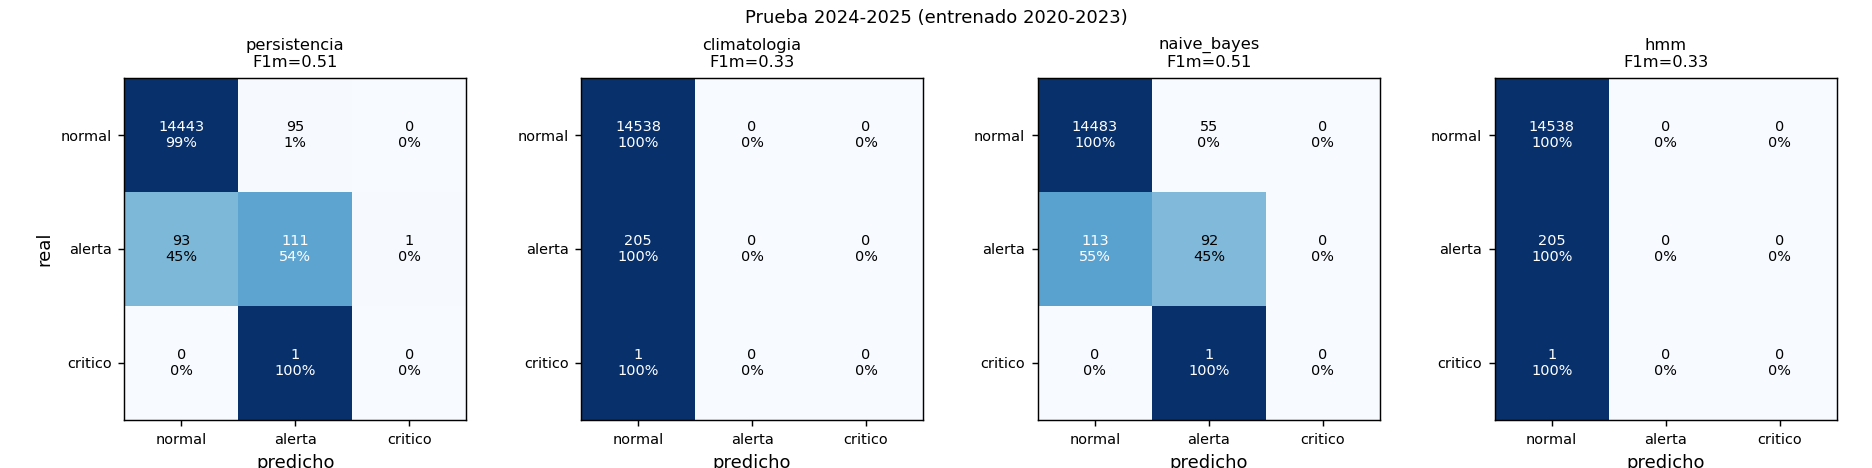

In [5]:
from IPython.display import Image
Image(str(FIGURES_DIR / 'confusion_test.png'))

## HMM: parámetros y convergencia

In [6]:
m['hmm_parametros']

{'mu_log': [2.451, 2.836, 3.215],
 'pm25_mediana_estado': [11.6, 17.1, 24.9],
 'sd_log': [0.269, 0.197, 0.212],
 'A': [[0.904, 0.096, 0.0], [0.058, 0.909, 0.034], [0.001, 0.052, 0.947]],
 'iteraciones': 33}

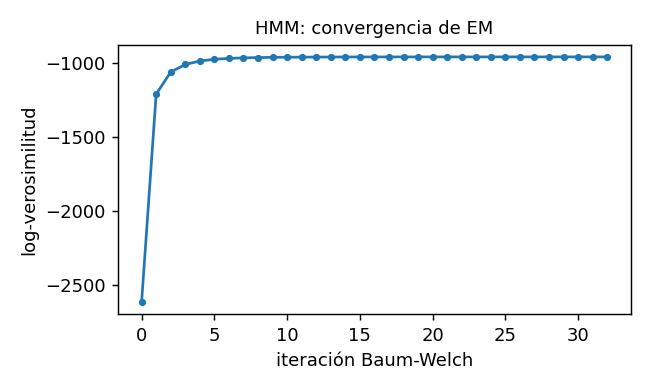

In [7]:
Image(str(FIGURES_DIR / 'hmm_loglik.png'))

## Interpretación honesta
- **NB vs. persistencia.** En F1 macro quedan prácticamente empatados (≈ 0,51). El NB acierta más cuando anuncia un episodio
  (precisión de alerta ≈ 0,63 vs 0,54) pero detecta menos episodios (recall ≈ 0,45 vs 0,55). Su ventaja real es que da
  **probabilidades calibrables**: log-loss 0,039 frente a 0,065 de la climatología.
- **Por qué no gana claramente.** El PM2.5 es muy persistente día a día y la información de hoy ya está en la persistencia.
  Las features meteorológicas son del día *t* (no hay pronóstico de *t+1*), vienen de un reanálisis de ~10 km que no resuelve el valle y se correlacionan poco con el PM2.5 de mañana (ver 01_eda).
- **HMM.** Sus 3 estados quedan en niveles de fondo (~12, 17, 25 µg/m³), no en episodios: el entrenamiento casi no tiene días de alerta
  (74 de 12 662). Como clasificador equivale a la climatología (nunca predice alerta), aunque su log-loss (0,058) es mejor.
  Es útil como descriptor del estado latente, no como alarma.
- **Clase crítico.** Hay un único día crítico en 2020–2025, así que el modelo no puede aprenderla; el F1 macro incluye esa clase con F1 = 0.
- **Ajuste probado y descartado.** Discretizar el nivel de hoy más fino cerca de 37 µg/m³ no mejoró la validación cruzada, así que no se adoptó.